In [1]:
import numpy as np
import matplotlib.pyplot as plt

n = 1001
# m = 9.1 *10**(-31)          # mass of electron in kg
h_bar = 1.054 * 10**(-34)  # Planck's constant in J*s
e = 1.6 * 10**(-19)        # elementary charge in C
Z = 1                      # Atomic number for hydrogen
# k = 8.99 * 10**9           # Coulomb's constant (1/4 pi epsilon_0) in N*m^2/C^2
a0 = 5.29 * 10**(-11)*10**(15)        # Bohr radius in m
E0 = -13.6   # eV, ground state energy of hydrogen
r_min = 0
r_max = 9   # fm
r = np.linspace(r_min, r_max, n)
delta_r = r[1] - r[0]
a = 0.1* 10**(-9)

In [2]:
k = 100     # MeV/fm^2
hbar_c = 197.327  # MeV fm
m = 940            # MeV/c^2
c = hbar_c**2 / (2*m*delta_r**2)

In [3]:
print(c)
print(delta_r)

255699.6646243762
0.009


In [21]:
ke = (-c) * ( np.eye((n-2), k = 1) + (-2)*np.eye(n-2) + np.eye((n-2), k = -1) ) # kinetic energy matrix
r_new = r[1:-1]  # new r values corresponding to the eigenvectors
# let count = 3
count = 3

mygod=0   #  running out of academic names
potential = np.zeros((len(r_new), count)) # for each b
gnd_state = np.zeros((len(r_new), count))

print("Inspecting", count, " states:")
for b in [0, 10, 30]:
    print("\nb =",b,"MeV/fm")
    v = (k*r*r /2) +(b * (r**3) /3)   # b is in MeV/fm^3
    pe = np.diag(v[1:-1])  # potential energy matrix

    Hamil = ke + pe     # This will be a radial Schrodinger equation for the hydrogen atom
    eig_val, eig_vec = np.linalg.eigh(Hamil)  # Eig_vec will give us u(r) = r*R(r) where R(r) is the radial wavefunction
    print("(Eigen values) energy ",eig_val[0:3], "MeV")  # print the ground state eigenvalues in eV
    # energy[:count] = eig_val[:count]
    psi = eig_vec
    delx = delta_r
    x_new = r_new
    # NORMALISE and store only bound-state wavefunctions
    for j in range(count):
        norm = np.sqrt(np.trapezoid(eig_vec[:, j]**2, r[1:-1]))
        eig_vec[:, j] = eig_vec[:, j]/norm           # psi[r_index, screening_index, state_index]       
    gnd_state[:,mygod] = eig_vec[:,mygod]
          
    exp_x = np.zeros(count)
    exp_x2 = np.zeros(count)
    exp_v = np.zeros(count)

    exp_p = np.zeros(count)
    exp_p2 = np.zeros(count)
    exp_ke = np.zeros(count)

    diff_psi = (psi[1:,:] - psi[:-1,:])/delx  # shape of diff_psi is (n-3, count)
    xmid = (x_new[1:] + x_new[:-1])/2  # x_i = (x[i] + x[i+1])/2;  (everything except the first - everything except the last)/2
    psi_mid = (psi[1:,:] + psi[:-1,:])/2
    diff2_psi = (diff_psi[1:,:] - diff_psi[:-1,:])/delx  # shape of diff2_psi is (n-4, count)
    psi_mid2 = psi[1:-1,:]  # shape of psi_mid2 is (n-4, count); exclude 1st & last point 
    xmid2 = x_new[1:-1]

    sigma_x = np.zeros(count)
    sigma_p = np.zeros(count)
    sigma_xp = np.zeros(count)

    print("Calculating expectation values for state:")
    for i in range(count):
        print("\n",i+1,") ")
        yp = x_new* psi[:,i]**2
        # <x> = psi(x)^2 * x
        exp_x[i]= np.trapezoid(yp, x_new)
        
        # <x^2> = psi(x)^2 * x^2
        yp2 = (x_new* psi[:,i])**2
        exp_x2[i] = np.trapezoid(yp2, x_new)
        
        # <V> = psi(x)^2 * V(x)
        yp3 = v[1:-1] * psi[:,i]**2
        #print("yp3 shape: ", yp3.shape, "xnew shape: ", xnew.shape)
        exp_v[i] = np.trapezoid(yp3, x_new)
        
        print("<x> = ", exp_x[i])
        print("<x^2> = ", exp_x2[i])
        print("<V> = ", exp_v[i])
        
        # <p> = -i*h_bar*(psi*(x) d(psi)/dx)
        yp4 = (psi_mid[:,i] * diff_psi[:,i])
        #print("yp4 shape: ", yp4.shape, "xmid shape: ", xmid.shape)
        exp_p[i] = (-1) * h_bar * np.trapezoid(yp4, xmid) 
        print("<p> = ", exp_p[i] * 1j)
        
        # <p^2> = -h_bar^2 *(psi*(x) d2(psi)/dx2)
        yp5 = psi_mid2[:,i]*diff2_psi[:,i]
        exp_p2[i]= np.trapezoid(yp5, xmid2) * (-1 * h_bar**2)
        print("<p^2> = ", exp_p2[i])
        
        # <k> = <p^2>/2m
        exp_ke[i] = exp_p2[i]/(2*m*e)
        print("<KE> = ", exp_ke[i])       
        print("Total energy = <KE> + <V> = ", exp_ke[i] + exp_v[i], f"MeV")
        
        # Uncertainty in x = sqrt(<x^2> - <x>^2)
        var_x = exp_x2[i] - (exp_x[i]**2)
        sigma_x[i] = np.sqrt(var_x)
        var_p = exp_p2[i] - (exp_p[i]**2)
        sigma_p[i] = np.sqrt(var_p)       
        sigma_xp[i] = sigma_x[i] * sigma_p[i]        
    print( "Ratio of (sigma_x * sigma_p)/(h_bar/2) :", (2 * sigma_xp/h_bar))
    potential[:,mygod] = v[1:-1]
    mygod+=1
    
    

Inspecting 3  states:

b = 0 MeV/fm


(Eigen values) energy  [ 96.54019061 225.25706962 353.96989829] MeV
Calculating expectation values for state:

 1 ) 
<x> =  0.9052344207799077
<x^2> =  0.9653907872350597
<V> =  48.269539361752976
<p> =  4.662544874710336e-38j
<p^2> =  2.589061027547488e-68
<KE> =  8.60725075647436e-53
Total energy = <KE> + <V> =  48.269539361752976 MeV

 2 ) 
<x> =  1.357827788564897
<x^2> =  2.25251279294516
<V> =  112.62563964725801
<p> =  6.990291507513273e-38j
<p^2> =  6.0410895578161444e-68
<KE> =  2.0083409434229202e-52
Total energy = <KE> + <V> =  112.62563964725801 MeV

 3 ) 
<x> =  1.6972545921335884
<x^2> =  3.539555132887423
<V> =  176.97775664437117
<p> =  8.733457113133563e-38j
<p^2> =  9.493078558243708e-68
<KE> =  3.155943669628892e-52
Total energy = <KE> + <V> =  176.97775664437117 MeV
Ratio of (sigma_x * sigma_p)/(h_bar/2) : [1.16640617 2.9820245  4.7456611 ]

b = 10 MeV/fm
(Eigen values) energy  [100.25916072 238.04323714 378.74786345] MeV
Calculating expectation values for state:

 

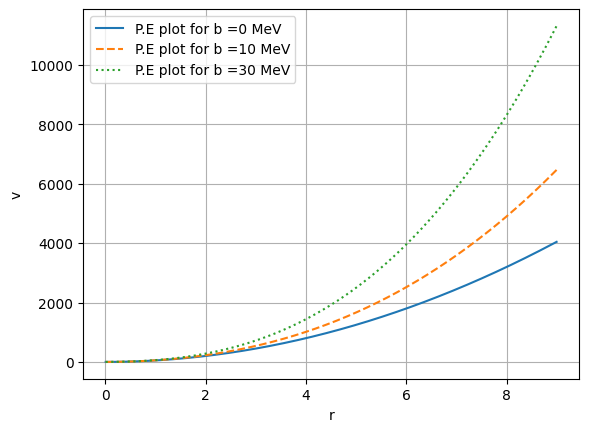

In [20]:
plt.plot(r_new, potential[:,0], label=f"P.E plot for b ={0} MeV")
plt.plot(r_new, potential[:,1], label=f"P.E plot for b ={10} MeV", ls="--")
plt.plot(r_new, potential[:,2], label=f"P.E plot for b ={30} MeV", ls=":")
plt.legend()
plt.xlabel("r")
plt.ylabel("v")
#plt.ylim(-10,200)
plt.grid()
plt.show()

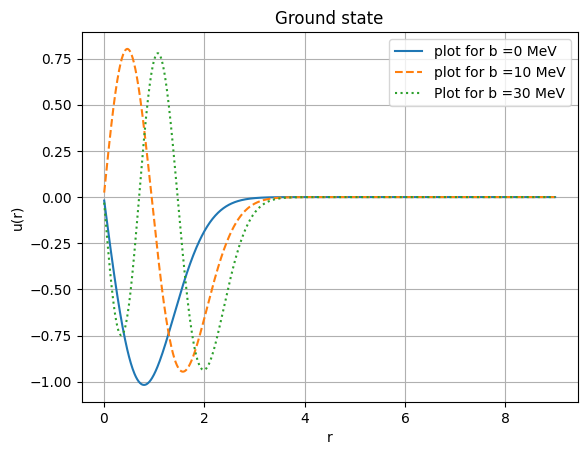

In [24]:
plt.plot(r_new, gnd_state[:,0], label=f"plot for b ={0} MeV")
plt.plot(r_new, gnd_state[:,1], label=f"plot for b ={10} MeV", ls="--")
plt.plot(r_new, gnd_state[:,2], label=f"Plot for b ={30} MeV", ls=":")
plt.legend()
plt.xlabel("r")
plt.ylabel("u(r)")
#plt.ylim(-10,200)
plt.title("Ground state")
plt.grid()
plt.show()

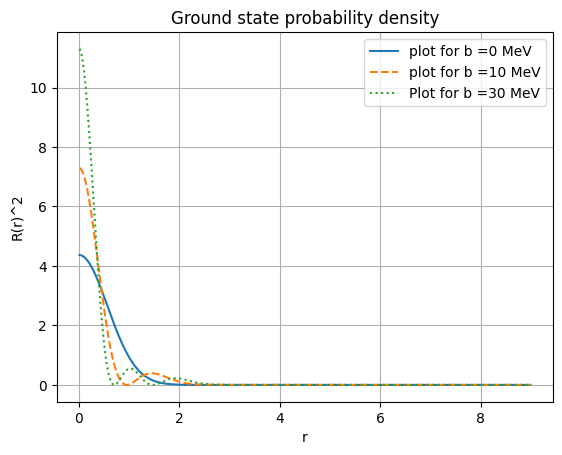

In [23]:
plt.plot(r_new, (gnd_state[:,0]/r_new)**2, label=f"plot for b ={0} MeV")
plt.plot(r_new, (gnd_state[:,1]/r_new)**2, label=f"plot for b ={10} MeV", ls="--")
plt.plot(r_new, (gnd_state[:,2]/r_new)**2, label=f"Plot for b ={30} MeV", ls=":")
plt.legend()
plt.xlabel("r")
plt.ylabel("R(r)^2")
#plt.ylim(-10,200)
plt.title("Ground state probability density")
plt.grid()
plt.show()